<a href="https://colab.research.google.com/github/vhvaldiviesor/Programacion-para-analitica-descriptiva-y-predictiva/blob/main/269711_01_semana12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Valdivieso Rodriguez, Victor Hugo
*   Matrícula: 269711

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

df = pd.read_csv("advertising.csv")

print(f"Dimensiones: {df.shape}")
display(df.head())

print("\nEstadísticas descriptivas:")
display(df.describe())

Dimensiones: (200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9



Estadísticas descriptivas:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

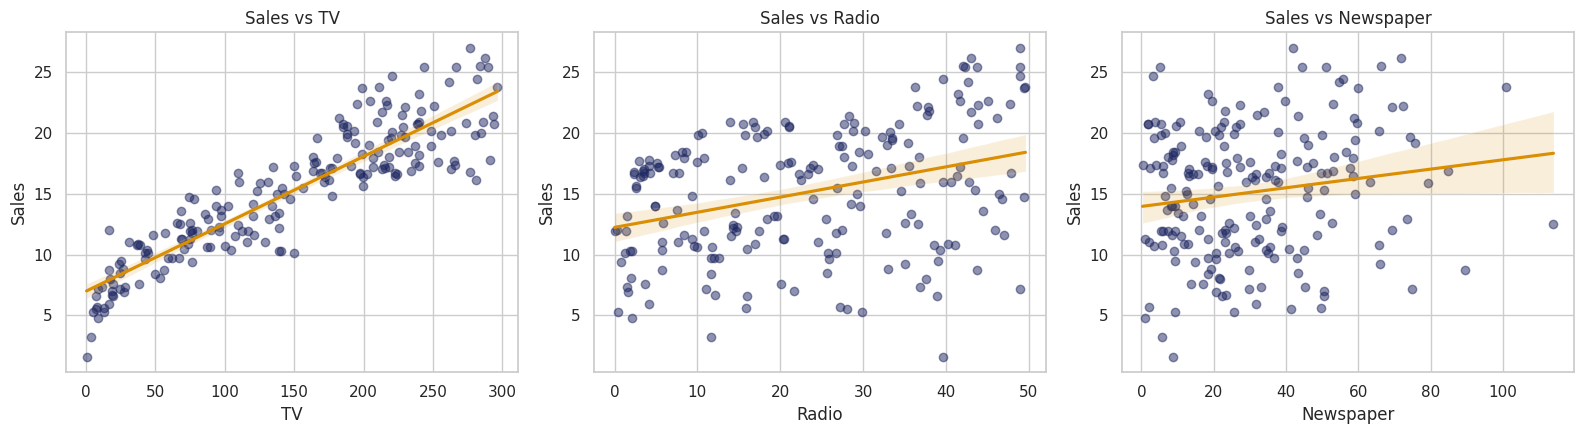

In [3]:
# Gráficos de dispersión
variables_predictoras = ["TV", "Radio", "Newspaper"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, variables_predictoras):
    sns.regplot(data=df, x=col, y="Sales", ax=ax,
                scatter_kws={"alpha": 0.5, "color": "#1E2761"},
                line_kws={"color": "#D98E04"})
    ax.set_title(f"Sales vs {col}")
plt.tight_layout()
plt.show()

**Interpretación.**

- `TV`: relación lineal clara y fuerte; a mayor inversión en TV, las ventas suben de forma consistente, con los puntos bien pegados a la línea de regresión.
- `Radio`: relación lineal positiva pero más dispersa que TV; la tendencia es visible, aunque hay más variabilidad alrededor de la línea.
- `Newspaper`: relación casi plana, con una pendiente positiva muy ligera y los puntos muy dispersos alrededor de la línea; a simple vista es la variable con la relación lineal más débil con `Sales`.

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

               TV   Radio  Newspaper   Sales
TV         1.0000  0.0548     0.0566  0.9012
Radio      0.0548  1.0000     0.3541  0.3496
Newspaper  0.0566  0.3541     1.0000  0.1580
Sales      0.9012  0.3496     0.1580  1.0000


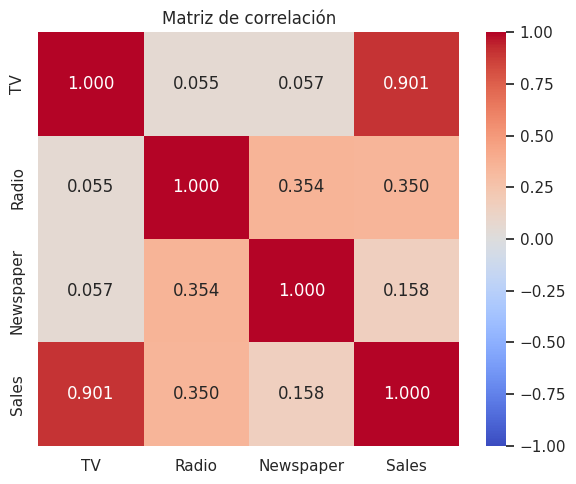

In [4]:
# Correlación y heatmap
matriz_corr = df.corr()
print(matriz_corr.round(4))

plt.figure(figsize=(6, 5))
sns.heatmap(matriz_corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

**Respuesta.**

- La variable más correlacionada con `Sales` es `TV` (r = 0.901), muy por encima de `Radio` (r = 0.350) y de `Newspaper` (r = 0.158, la más débil de las tres).
- Entre los predictores, la correlación es baja: `TV`-`Radio` = 0.055, `TV`-`Newspaper` = 0.057, y `Radio`-`Newspaper` = 0.354, la más alta de las tres pero aún moderada, no alta. No hay indicios de correlación alta entre predictores a partir de esta matriz.

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

    variable       VIF
0         TV  1.004611
1      Radio  1.144952
2  Newspaper  1.145187


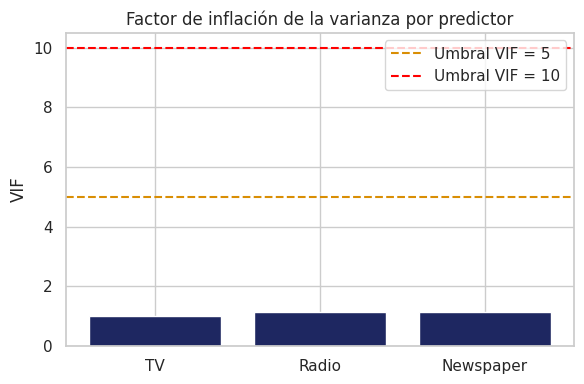

In [5]:
#Multicolinealidad
X_vif = sm.add_constant(df[variables_predictoras])
vif_datos = pd.DataFrame({
    "variable": variables_predictoras,
    "VIF": [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(variables_predictoras))],
})
print(vif_datos)

plt.figure(figsize=(6, 4))
plt.bar(vif_datos["variable"], vif_datos["VIF"], color="#1E2761")
plt.axhline(5, color="#D98E04", linestyle="--", label="Umbral VIF = 5")
plt.axhline(10, color="red", linestyle="--", label="Umbral VIF = 10")
plt.ylabel("VIF")
plt.title("Factor de inflación de la varianza por predictor")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación.**

Los VIF obtenidos son: `TV` = 1.005, `Radio` = 1.145 y `Newspaper` = 1.145. Ninguna variable tiene un VIF mayor a 5 (y mucho menos mayor a 10); de hecho, los tres valores están muy cerca de 1, que es el mínimo posible (equivale a "nula multicolinealidad"). Esto es consistente con la matriz de correlación de la parte 2.2, donde ningún par de predictores mostró correlación alta.

**Implicación para el modelo:** no hay evidencia de multicolinealidad entre `TV`, `Radio` y `Newspaper`. Los coeficientes del modelo de regresión múltiple se pueden estimar e interpretar con confianza (errores estándar no inflados por redundancia entre predictores), y no es necesario eliminar ninguna variable por este criterio.

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [6]:
#ntrenamiento del Modelo (Todas las Variables Independientes)
X1 = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

modelo1 = LinearRegression()
modelo1.fit(X1, y)

print("Intercepto:", modelo1.intercept_)
print("Coeficientes:")
for var, coef in zip(X1.columns, modelo1.coef_):
    print(f"  {var}: {coef:.5f}")

Intercepto: 4.625124078808653
Coeficientes:
  TV: 0.05445
  Radio: 0.10700
  Newspaper: 0.00034


**Interpretación.**

- **Intercepto (4.6251):** si no se invirtiera nada en TV, Radio ni Newspaper (las tres variables en 0), el modelo predice ventas promedio de 4.63 unidades. Es un valor principalmente técnico (ancla la recta), no necesariamente un escenario realista del negocio.
- **TV (0.0544):** por cada unidad adicional de inversión en TV (manteniendo Radio y Newspaper fijos), las ventas aumentan en promedio 0.0544 unidades.
- **Radio (0.1070):** por cada unidad adicional de inversión en Radio (manteniendo TV y Newspaper fijos), las ventas aumentan en promedio 0.1070 unidades, casi el doble que el efecto marginal de TV.
- **Newspaper (0.0003):** el efecto marginal de Newspaper es prácticamente nulo (sube las ventas solo 0.0003 unidades por unidad invertida); se confirmará en la parte 4.7 si este coeficiente es estadísticamente distinto de cero.

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

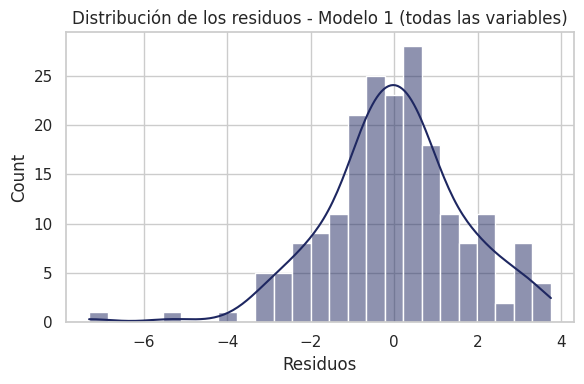

Media de los residuos: -0.000000
Asimetría (skew): -0.4311
Curtosis: 1.6048
Shapiro-Wilk: estadístico=0.9758, p-value=0.0016


In [7]:
#Normalidad de los residuos
y_pred1 = modelo1.predict(X1)
residuos1 = y - y_pred1

plt.figure(figsize=(6, 4))
sns.histplot(residuos1, kde=True, color="#1E2761", bins=25)
plt.xlabel("Residuos")
plt.title("Distribución de los residuos - Modelo 1 (todas las variables)")
plt.tight_layout()
plt.show()

print(f"Media de los residuos: {residuos1.mean():.6f}")
print(f"Asimetría (skew): {stats.skew(residuos1):.4f}")
print(f"Curtosis: {stats.kurtosis(residuos1):.4f}")

shapiro_stat, shapiro_p = stats.shapiro(residuos1)
print(f"Shapiro-Wilk: estadístico={shapiro_stat:.4f}, p-value={shapiro_p:.4f}")

**Respuesta.**

A simple vista el histograma con KDE se ve razonablemente acampanado y centrado en 0, pero no es perfectamente simétrico: tiene una asimetría negativa (skew = -0.431) y colas un poco más pesadas que una normal (curtosis = 1.60 en exceso, equivalente a curtosis de Fisher-Pearson de 4.60 según el resumen de statsmodels). La prueba de Shapiro-Wilk lo confirma formalmente: p-value = 0.0016, menor a 0.05, por lo que se **rechaza** la hipótesis de normalidad de los residuos. Es una desviación moderada, no severa (visualmente se parece a una normal), pero formalmente no cumple el supuesto al 100%.

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

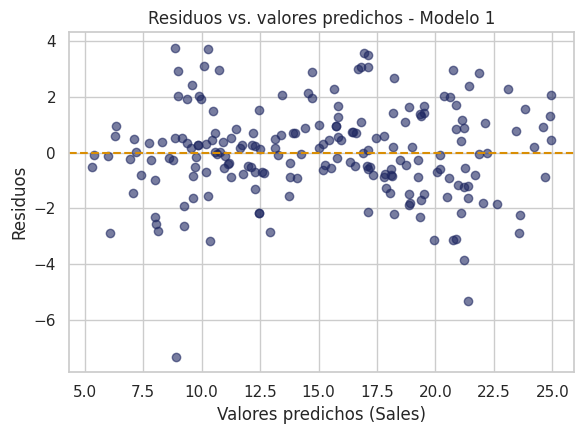

Prueba de Breusch-Pagan: estadístico=3.9785, p-value=0.2638


In [8]:
# Homocedasticidad
plt.figure(figsize=(6, 4.5))
plt.scatter(y_pred1, residuos1, alpha=0.6, color="#1E2761")
plt.axhline(0, color="#D98E04", linestyle="--")
plt.xlabel("Valores predichos (Sales)")
plt.ylabel("Residuos")
plt.title("Residuos vs. valores predichos - Modelo 1")
plt.tight_layout()
plt.show()

Xc1 = sm.add_constant(X1)
bp_stat1, bp_p1, _, _ = het_breuschpagan(residuos1, Xc1)
print(f"Prueba de Breusch-Pagan: estadístico={bp_stat1:.4f}, p-value={bp_p1:.4f}")

**Respuesta.**

En la gráfica no se observa un patrón claro tipo "embudo" o curva; los residuos se dispersan de forma razonablemente aleatoria alrededor de 0 en todo el rango de valores predichos, aunque hay un ligero agrupamiento de residuos negativos grandes en la zona de predicciones bajas. La prueba de Breusch-Pagan apoya la lectura visual: p-value = 0.264, mayor a 0.05, por lo que no se rechaza la hipótesis nula de homocedasticidad (varianza constante de los residuos). El supuesto de homocedasticidad se cumple razonablemente bien.

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

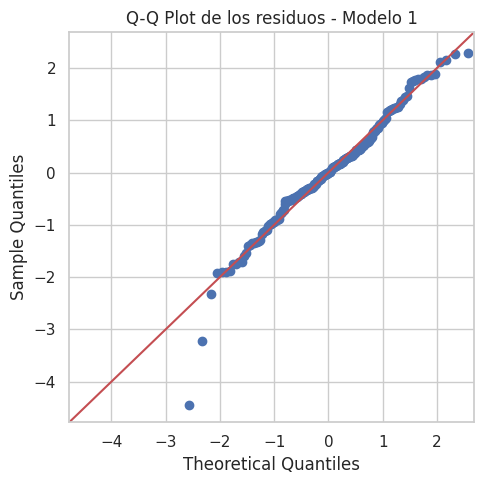

In [9]:
#Q-Q Plot
fig = sm.qqplot(residuos1, line="45", fit=True)
fig.set_size_inches(5, 5)
plt.title("Q-Q Plot de los residuos - Modelo 1")
plt.tight_layout()
plt.show()

**Interpretación.**

La mayoría de los puntos centrales se alinean bien sobre la diagonal, pero en ambos extremos (sobre todo en la cola izquierda, de residuos muy negativos) los puntos se desvían de la línea de 45°. Esta desviación sistemática en las colas es consistente con la asimetría negativa y el exceso de curtosis detectados en 4.2, y confirma gráficamente lo que ya había señalado la prueba de Shapiro-Wilk: los residuos se acercan a una distribución normal en el centro, pero no son perfectamente normales en los extremos.

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [10]:
#Evaluación del Modelo
mse1 = mean_squared_error(y, y_pred1)
rmse1 = np.sqrt(mse1)
r2_1 = r2_score(y, y_pred1)

print(f"MSE:  {mse1:.4f}")
print(f"RMSE: {rmse1:.4f}")
print(f"R²:   {r2_1:.4f}")

MSE:  2.7060
RMSE: 1.6450
R²:   0.9026


**Respuesta.**

El modelo explica el 90.26% de la variabilidad de `Sales` (R² = 0.9026), un ajuste muy bueno para un modelo lineal con solo tres predictores. El RMSE de 1.645 indica que, en promedio, las predicciones del modelo se desvían de las ventas reales en aproximadamente 1.65 unidades, un error pequeño frente al rango de `Sales` en los datos (de 1.6 a 27.0, con media de 15.1). En conjunto, las métricas muestran un modelo con buen poder predictivo.

### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

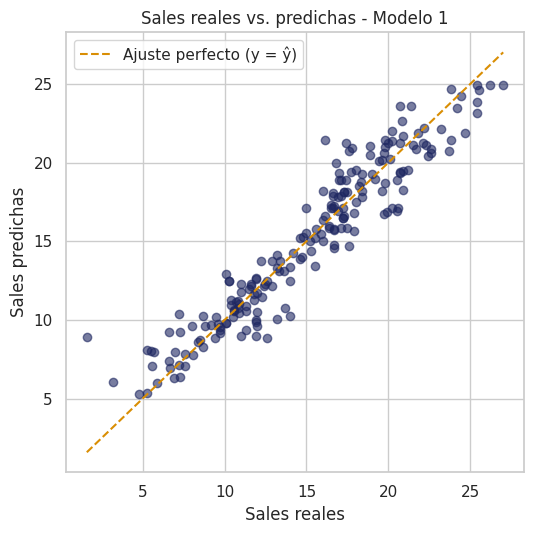

In [11]:
#Visualización de las Predicciones
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y, y_pred1, alpha=0.6, color="#1E2761")
lims = [min(y.min(), y_pred1.min()), max(y.max(), y_pred1.max())]
plt.plot(lims, lims, color="#D98E04", linestyle="--", label="Ajuste perfecto (y = ŷ)")
plt.xlabel("Sales reales")
plt.ylabel("Sales predichas")
plt.title("Sales reales vs. predichas - Modelo 1")
plt.legend()
plt.tight_layout()
plt.show()

**Respuesta.**

Los puntos se agrupan de forma cercana alrededor de la línea de ajuste perfecto (y = ŷ), lo cual es consistente con el R² alto (0.9026) calculado en 4.5. No hay una curvatura sistemática que sugiera que el modelo subestima o sobreestima sistemáticamente en algún rango de ventas, aunque hay algo más de dispersión en las ventas más bajas y más altas que en el rango medio. Esta gráfica es un buen chequeo visual complementario a las métricas numéricas: confirma que el modelo captura bien la tendencia general, sin errores sistemáticos grandes concentrados en un extremo.

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [12]:
#P-values
X1_sm = sm.add_constant(X1)
modelo1_sm = sm.OLS(y, X1_sm).fit()
print(modelo1_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        07:43:27   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

**Interpretación.**

En la tabla `P>|t|`: `const` (p < 0.001), `TV` (p < 0.001) y `Radio` (p < 0.001) tienen p-value muy por debajo de 0.05. `Newspaper`, en cambio, tiene p-value = 0.954, muy por encima de 0.05.

**Conclusión:** `TV` y `Radio` son estadísticamente significativas para explicar `Sales` dentro de este modelo: hay evidencia fuerte de que su efecto sobre las ventas es distinto de cero, incluso controlando por las otras variables. `Newspaper`, en cambio, no es estadísticamente significativa: no se puede rechazar la hipótesis de que su coeficiente verdadero sea 0 una vez que ya se tiene a `TV` y `Radio` en el modelo. Esto es consistente con que `Newspaper` tenía, desde la parte 2.1 y 2.2, la relación lineal más débil con `Sales` de las tres variables.

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

**Nota antes de empezar.** En la parte 3 ningún predictor tuvo VIF mayor a 5 (todos entre 1.00 y 1.15), así que **no se detectó multicolinealidad** y no hay ninguna variable que eliminar por este criterio. Por lo tanto, el Modelo 2 de esta parte usa las mismas tres variables que el Modelo 1 (`TV`, `Radio`, `Newspaper`), y es de esperarse que sus resultados sean prácticamente idénticos a los de la Parte 4. Se repiten los pasos completos, como pide la consigna, para dejar la evidencia explícita.

### 5.1 Entrenamiento del Modelo (sin variables eliminadas: ninguna presentaba multicolinealidad)

1. Entrena un modelo de regresión lineal múltiple (mismas variables que la Parte 4, ya que ninguna presentaba multicolinealidad).
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno.

In [13]:
# Entrenamiento del Modelo 2 (sin eliminar variables: ninguna tenía VIF > 5)
X2 = df[["TV", "Radio", "Newspaper"]].copy()  # idénticas a la Parte 4

modelo2 = LinearRegression()
modelo2.fit(X2, y)

print("Intercepto:", modelo2.intercept_)
print("Coeficientes:")
for var, coef in zip(X2.columns, modelo2.coef_):
    print(f"  {var}: {coef:.5f}")

Intercepto: 4.625124078808653
Coeficientes:
  TV: 0.05445
  Radio: 0.10700
  Newspaper: 0.00034


**Interpretación.** Como se anticipó, el intercepto (4.6251) y los tres coeficientes (`TV`=0.0544, `Radio`=0.1070, `Newspaper`=0.0003) son idénticos a los del Modelo 1: al no eliminar ninguna variable, el ajuste de mínimos cuadrados da exactamente la misma solución.

### 5.2 Normalidad de los residuos

1. Calcula los residuos.
2. Grafica un histograma con KDE.
3. ¿Los residuos parecen distribuirse normalmente?

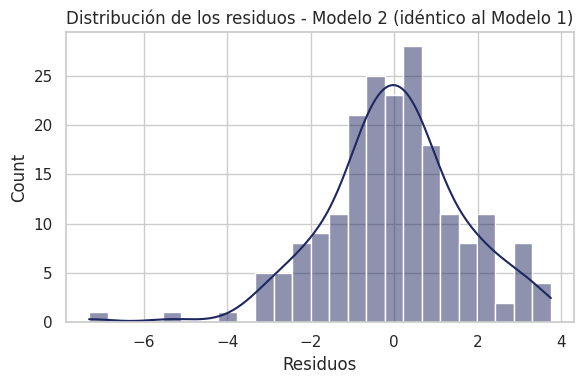

Shapiro-Wilk: estadístico=0.9758, p-value=0.0016


In [14]:
y_pred2 = modelo2.predict(X2)
residuos2 = y - y_pred2

plt.figure(figsize=(6, 4))
sns.histplot(residuos2, kde=True, color="#1E2761", bins=25)
plt.xlabel("Residuos")
plt.title("Distribución de los residuos - Modelo 2 (idéntico al Modelo 1)")
plt.tight_layout()
plt.show()

shapiro_stat2, shapiro_p2 = stats.shapiro(residuos2)
print(f"Shapiro-Wilk: estadístico={shapiro_stat2:.4f}, p-value={shapiro_p2:.4f}")

**Respuesta.** Mismo resultado que en 4.2: residuos razonablemente acampanados pero con asimetría negativa leve y colas algo pesadas; Shapiro-Wilk rechaza normalidad estricta (p = 0.0016), por tratarse exactamente del mismo modelo.

### 5.3 Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones?

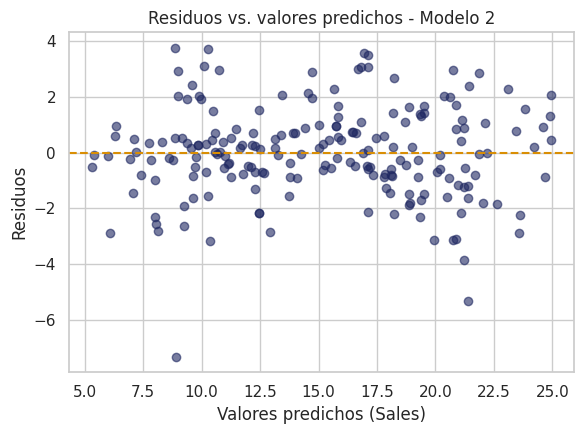

In [15]:
plt.figure(figsize=(6, 4.5))
plt.scatter(y_pred2, residuos2, alpha=0.6, color="#1E2761")
plt.axhline(0, color="#D98E04", linestyle="--")
plt.xlabel("Valores predichos (Sales)")
plt.ylabel("Residuos")
plt.title("Residuos vs. valores predichos - Modelo 2")
plt.tight_layout()
plt.show()

**Respuesta.** Igual que en 4.3: no hay un patrón tipo embudo evidente, los residuos se dispersan razonablemente alrededor de 0 (la prueba de Breusch-Pagan de 4.3, p = 0.264, aplica exactamente igual porque el modelo es el mismo).

### 5.4 Q-Q Plot

1. Graficar el Q-Q Plot.
2. Interpreta el gráfico.

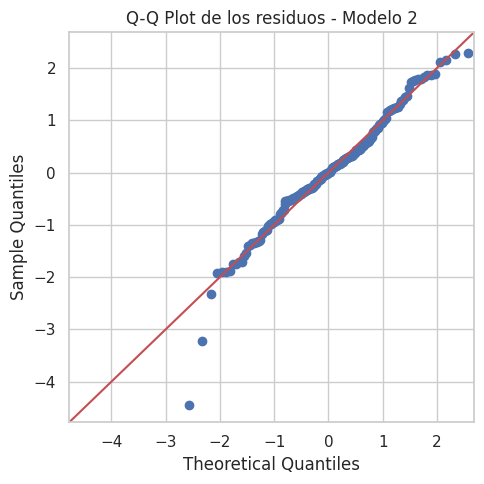

In [16]:
fig = sm.qqplot(residuos2, line="45", fit=True)
fig.set_size_inches(5, 5)
plt.title("Q-Q Plot de los residuos - Modelo 2")
plt.tight_layout()
plt.show()

**Interpretación.** Mismo patrón que en 4.4: buen ajuste a la diagonal en el centro, con desviaciones en las colas, coherente con la asimetría y curtosis ya reportadas.

### 5.5 Evaluación del Modelo

1. Calcula MSE, RMSE y R².
2. ¿Qué nos dicen estas métricas?

In [17]:
mse2 = mean_squared_error(y, y_pred2)
rmse2 = np.sqrt(mse2)
r2_2 = r2_score(y, y_pred2)

print(f"MSE:  {mse2:.4f}")
print(f"RMSE: {rmse2:.4f}")
print(f"R²:   {r2_2:.4f}")

MSE:  2.7060
RMSE: 1.6450
R²:   0.9026


**Respuesta.** MSE = 2.7060, RMSE = 1.6450, R² = 0.9026: valores idénticos (hasta redondeo) a los de la Parte 4, porque el Modelo 2 es el mismo modelo que el Modelo 1.

### 5.6 Visualización de Predicciones

1. Sales reales vs. predichas.

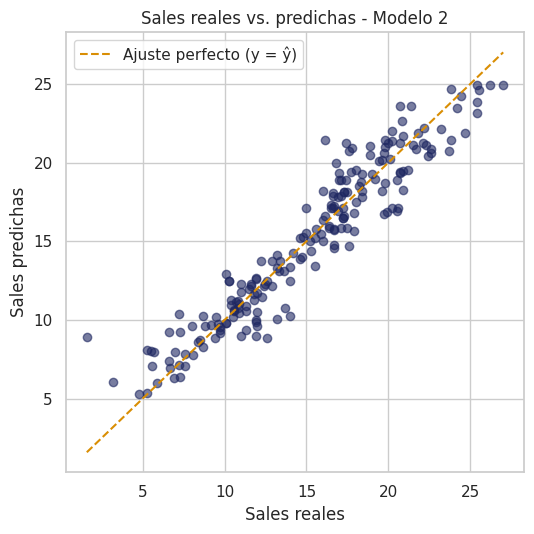

In [18]:
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y, y_pred2, alpha=0.6, color="#1E2761")
lims = [min(y.min(), y_pred2.min()), max(y.max(), y_pred2.max())]
plt.plot(lims, lims, color="#D98E04", linestyle="--", label="Ajuste perfecto (y = ŷ)")
plt.xlabel("Sales reales")
plt.ylabel("Sales predichas")
plt.title("Sales reales vs. predichas - Modelo 2")
plt.legend()
plt.tight_layout()
plt.show()

**Respuesta.** Gráfica idéntica a la de 4.6, por la misma razón: el Modelo 2 no cambió ninguna variable respecto al Modelo 1.

### 5.7 Verificar el impacto de los atributos en el modelo (statsmodels)

In [19]:
X2_sm = sm.add_constant(X2)
modelo2_sm = sm.OLS(y, X2_sm).fit()
print(modelo2_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        07:43:28   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

**Interpretación.** Misma tabla que en 4.7: `TV` y `Radio` significativas (p < 0.001), `Newspaper` no significativa (p = 0.954). Esta falta de significancia de `Newspaper` es justamente el criterio que se usa en la Parte 6 para eliminarla, aunque no por multicolinealidad sino por tener una relación lineal débil/no significativa con `Sales`.

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

**Nota antes de empezar.** De la Parte 2.1 (regplot casi plano), la Parte 2.2 (correlación con `Sales` de solo 0.158, la más baja de las tres) y la Parte 4.7 (p-value = 0.954, no significativa), `Newspaper` es consistentemente la variable sin una relación lineal clara con `Sales`. El Modelo 3 de esta parte se construye eliminando `Newspaper` y usando solo `TV` y `Radio`.

### 6.1 Entrenamiento del Modelo (sin `Newspaper`)

1. Entrena un modelo de regresión lineal múltiple usando `TV` y `Radio`.
2. Imprime el intercepto y los coeficientes.
3. Interpreta cada uno.

In [20]:
# Entrenamiento del Modelo 3: se elimina Newspaper por no tener relación lineal con Sales
X3 = df[["TV", "Radio"]]

modelo3 = LinearRegression()
modelo3.fit(X3, y)

print("Intercepto:", modelo3.intercept_)
print("Coeficientes:")
for var, coef in zip(X3.columns, modelo3.coef_):
    print(f"  {var}: {coef:.5f}")

Intercepto: 4.630879464097768
Coeficientes:
  TV: 0.05445
  Radio: 0.10717


**Interpretación.** El intercepto sube ligeramente a 4.6309 (de 4.6251) y los coeficientes de `TV` (0.05445) y `Radio` (0.10717) prácticamente no cambian respecto al Modelo 1 (0.05445 y 0.10700): esto confirma, desde otro ángulo, lo que ya decía el VIF bajo de la Parte 3: quitar `Newspaper` casi no afecta la estimación de los otros dos coeficientes porque no compartía información relevante con ellos. Se interpretan igual que antes: cada unidad adicional invertida en TV sube las ventas en promedio 0.0544 unidades, y cada unidad en Radio las sube 0.1072 unidades, manteniendo la otra variable fija.

### 6.2 Normalidad de los residuos

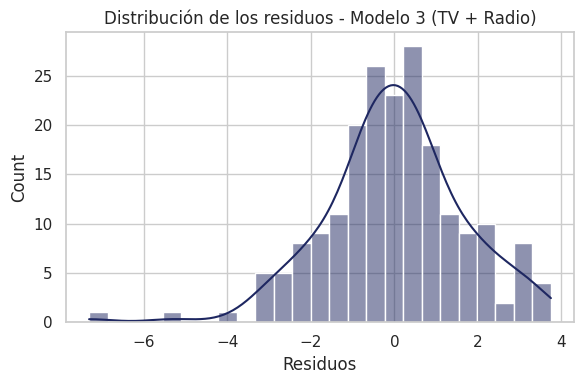

Shapiro-Wilk: estadístico=0.9757, p-value=0.0015


In [21]:
y_pred3 = modelo3.predict(X3)
residuos3 = y - y_pred3

plt.figure(figsize=(6, 4))
sns.histplot(residuos3, kde=True, color="#1E2761", bins=25)
plt.xlabel("Residuos")
plt.title("Distribución de los residuos - Modelo 3 (TV + Radio)")
plt.tight_layout()
plt.show()

shapiro_stat3, shapiro_p3 = stats.shapiro(residuos3)
print(f"Shapiro-Wilk: estadístico={shapiro_stat3:.4f}, p-value={shapiro_p3:.4f}")

**Respuesta.** Prácticamente igual que en los modelos 1 y 2: forma acampanada con asimetría negativa leve; Shapiro-Wilk también rechaza normalidad estricta (p = 0.0015). Quitar `Newspaper` no corrige ni empeora de forma relevante el comportamiento de los residuos.

### 6.3 Homocedasticidad

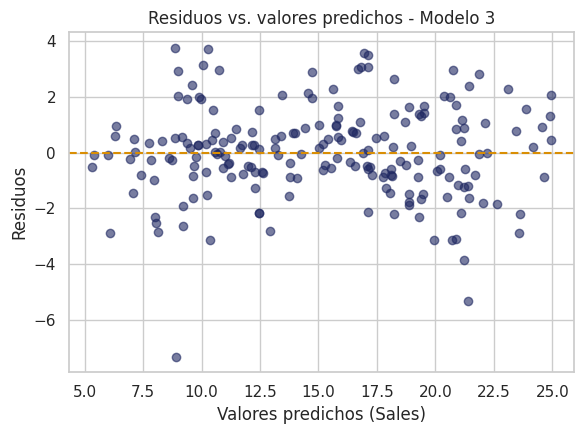

Prueba de Breusch-Pagan: estadístico=0.2374, p-value=0.8881


In [22]:
plt.figure(figsize=(6, 4.5))
plt.scatter(y_pred3, residuos3, alpha=0.6, color="#1E2761")
plt.axhline(0, color="#D98E04", linestyle="--")
plt.xlabel("Valores predichos (Sales)")
plt.ylabel("Residuos")
plt.title("Residuos vs. valores predichos - Modelo 3")
plt.tight_layout()
plt.show()

X3_sm = sm.add_constant(X3)
bp_stat3, bp_p3, _, _ = het_breuschpagan(residuos3, X3_sm)
print(f"Prueba de Breusch-Pagan: estadístico={bp_stat3:.4f}, p-value={bp_p3:.4f}")

**Respuesta.** No se observa un patrón sistemático; la prueba de Breusch-Pagan da p = 0.888, muy por encima de 0.05, así que no se rechaza homocedasticidad (incluso con más margen que en los modelos 1 y 2).

### 6.4 Q-Q Plot

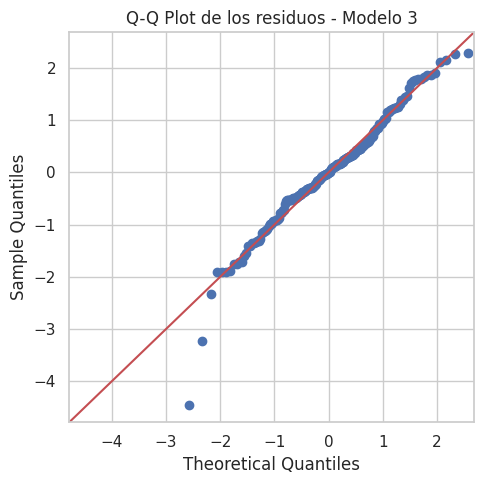

In [23]:
fig = sm.qqplot(residuos3, line="45", fit=True)
fig.set_size_inches(5, 5)
plt.title("Q-Q Plot de los residuos - Modelo 3")
plt.tight_layout()
plt.show()

**Interpretación.** Mismo patrón que en los modelos anteriores: buen ajuste en el centro, desviaciones leves en las colas; consistente con una distribución aproximadamente normal, con desviaciones menores.

### 6.5 Evaluación del Modelo

In [24]:
mse3 = mean_squared_error(y, y_pred3)
rmse3 = np.sqrt(mse3)
r2_3 = r2_score(y, y_pred3)

print(f"MSE:  {mse3:.4f}")
print(f"RMSE: {rmse3:.4f}")
print(f"R²:   {r2_3:.4f}")

MSE:  2.7061
RMSE: 1.6450
R²:   0.9026


**Respuesta.** MSE = 2.7061, RMSE = 1.6450, R² = 0.9026: prácticamente idénticos a los del Modelo 1 (que sí incluía `Newspaper`). Eliminar una variable que no aportaba relación lineal no empeoró el ajuste del modelo.

### 6.6 Visualización de Predicciones

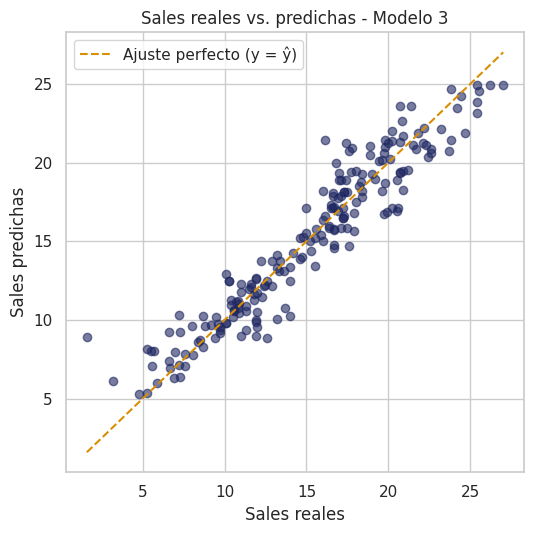

In [25]:
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y, y_pred3, alpha=0.6, color="#1E2761")
lims = [min(y.min(), y_pred3.min()), max(y.max(), y_pred3.max())]
plt.plot(lims, lims, color="#D98E04", linestyle="--", label="Ajuste perfecto (y = ŷ)")
plt.xlabel("Sales reales")
plt.ylabel("Sales predichas")
plt.title("Sales reales vs. predichas - Modelo 3")
plt.legend()
plt.tight_layout()
plt.show()

**Respuesta.** Los puntos se agrupan igual de cerca de la línea de ajuste perfecto que en el Modelo 1; visualmente no se distingue una diferencia relevante en el ajuste al quitar `Newspaper`.

### 6.7 Verificar el impacto de los atributos en el modelo (statsmodels)

In [26]:
modelo3_sm = sm.OLS(y, X3_sm).fit()
print(modelo3_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     912.7
Date:                Sat, 31 Oct 2026   Prob (F-statistic):          2.39e-100
Time:                        07:43:31   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             772.7
Df Residuals:                     197   BIC:                             782.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6309      0.290     15.952      0.0

**Interpretación.** `TV` y `Radio` siguen siendo altamente significativas (p < 0.001 ambas). El R² ajustado del Modelo 3 (0.902) es ligeramente **mayor** que el del Modelo 1 (0.901), a pesar de tener una variable menos: esto es evidencia adicional de que `Newspaper` no aportaba información útil al modelo, solo "ruido" que penalizaba el R² ajustado por el grado de libertad extra que consumía.

##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

In [27]:
resumen_modelos = pd.DataFrame({
    "modelo": ["Modelo 1: TV + Radio + Newspaper", "Modelo 2: TV + Radio + Newspaper (sin multicolinealidad)", "Modelo 3: TV + Radio (sin Newspaper)"],
    "n_variables": [3, 3, 2],
    "MSE": [mse1, mse2, mse3],
    "RMSE": [rmse1, rmse2, rmse3],
    "R2": [r2_1, r2_2, r2_3],
    "R2_ajustado": [modelo1_sm.rsquared_adj, modelo2_sm.rsquared_adj, modelo3_sm.rsquared_adj],
})
resumen_modelos

,modelo,n_variables,MSE,RMSE,R2,R2_ajustado
0,Modelo 1: TV + Radio + Newspaper,3,2.706006,1.644994,0.902591,0.901100
1,Modelo 2: TV + Radio + Newspaper (sin multicol...,3,2.706006,1.644994,0.902591,0.901100
2,Modelo 3: TV + Radio (sin Newspaper),2,2.706053,1.645008,0.902590,0.901601


**Respuesta.**

**¿Cuál de los tres modelos fue el mejor?** El Modelo 2 es, por construcción, idéntico al Modelo 1 (no se eliminó ninguna variable porque no había multicolinealidad), así que la comparación real es entre el Modelo 1/2 (con `Newspaper`) y el Modelo 3 (sin `Newspaper`). Los tres tienen prácticamente el mismo RMSE (≈1.645) y el mismo R² (≈0.9026), pero el Modelo 3 logra ese desempeño con una variable menos y tiene el R² ajustado más alto (0.902 vs. 0.901). Por el principio de parsimonia (un modelo más simple que explica lo mismo es preferible) y porque en el Modelo 3 todas las variables que quedan son estadísticamente significativas (p < 0.001), el **Modelo 3 (TV + Radio) es el mejor** de los tres: es el más simple, el más fácil de interpretar y de mantener, y no pierde poder predictivo frente a incluir `Newspaper`.

**¿Cuál fue el atributo con más influencia en las ventas?** Depende de qué se entienda por "influencia":

- Si se trata de qué tan bien explica las ventas por sí sola, es **`TV`**, por mucho: tiene la correlación más alta con `Sales` (r = 0.901) y, en una regresión simple solo con `TV`, ya explica el 81.2% de la variabilidad de las ventas (R² = 0.812) — la mayor parte del 90.3% que logra el modelo completo.
- Si se trata del efecto marginal por unidad de gasto, controlando por las demás variables, es **`Radio`**: su coeficiente (≈0.107) es casi el doble que el de `TV` (≈0.054) en todos los modelos ajustados. Esto significa que, peso por peso invertido, Radio impulsa más las ventas que TV; lo que pasa es que, en los datos, el presupuesto de TV es mucho mayor y varía mucho más (media de 147.0 frente a 23.3 de Radio), por lo que en la práctica TV termina explicando una porción mayor de la variación total observada en las ventas.

En conjunto, `TV` es el predictor dominante del modelo en términos de poder explicativo global, pero `Radio` es el más eficiente en términos de efecto por unidad de inversión; `Newspaper`, con base en toda la evidencia de las partes 2, 4.7 y 6, no tiene una influencia relevante sobre las ventas una vez que se controla por TV y Radio.